<a href="https://colab.research.google.com/github/EhsanGhasemi423/INFS-8368/blob/main/RNN_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recurrent Neural Networks

So far, we have studied two major types of data:

- **Tabular data**, where each example contains a fixed number of features.
- **Image data**, where every image has a fixed height and width.

These data types have a fixed size, allowing traditional neural networks and convolutional neural networks (CNNs) to process one input and produce one output.

However, many real-world problems involve **sequences**, where the input or output length may vary. Examples include:

- Text and language translation
- Speech recognition
- Time-series forecasting
- Video analysis
- Music generation

These applications require models that can remember information from previous time steps while processing new inputs. Recurrent Neural Networks (RNNs) were developed to address this challenge.


## Why Recurrent Neural Networks?

Unlike feedforward neural networks, which process each input independently, RNNs introduce a **recurrent connection** that passes information from one time step to the next.

This allows the network to retain information about previous inputs, making it suitable for sequential data.

For example, when reading a sentence, the meaning of the current word often depends on the words that came before it. An RNN maintains a hidden state that carries this information throughout the sequence.

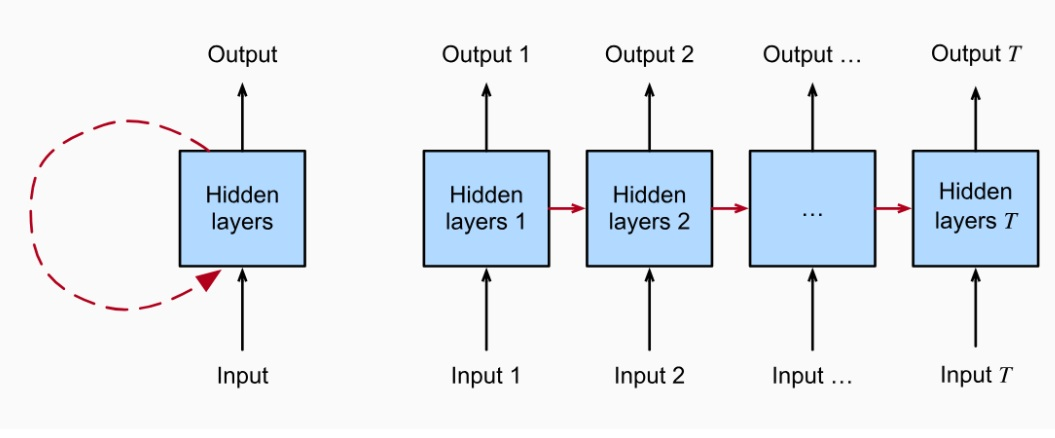

The figure illustrates two equivalent views of an RNN.

- **Left:** A recurrent connection loops back into the hidden layer, allowing information from previous inputs to be remembered.
- **Right:** The same network is "unrolled" across multiple time steps. Each hidden layer represents the network at a different point in time, while sharing the same model parameters.

The hidden state transfers information from one time step to the next, enabling the network to learn sequential patterns.

## Working with Sequences

So far, most of the data we have worked with has had a fixed structure. With **sequential data**, however, the order of observations matters.

A sequence can be written as:

$$
x_1, x_2, x_3, \ldots, x_T
$$

where $x_t$ represents the observation at **time step $t$**.

Examples of sequences include:

- Words in a sentence
- Daily stock prices
- Sensor measurements over time
- Frames in a video
- Audio samples

The key difference is that observations in a sequence are usually **not independent**. What happens at one time step may depend on what happened earlier.

For example, consider the sentence:

> **The dog is chasing the ____**

The previous words provide information that helps us predict the next word. Therefore, a sequence model must be able to use information from earlier time steps when processing the current time step.

This dependence between observations is the main reason we need specialized **sequence models**, such as recurrent neural networks (RNNs).

### Sequence Notation

A sequence contains an ordered collection of observations:

$$
x_1, x_2, \ldots, x_T
$$

where:

- $x_1$ is the first observation.
- $x_2$ is the second observation.
- $x_t$ is the observation at time step $t$.
- $T$ is the total length of the sequence.

For example, suppose we record temperature for five consecutive days:

$$
72,\ 75,\ 73,\ 78,\ 80
$$

Then:

$$
x_1 = 72,\qquad x_2 = 75,\qquad T = 5
$$

Unlike ordinary tabular data, **changing the order changes the meaning of the sequence**.

### Some basic intuitions: Autoregression?

Before introducing RNNs, we first need to understand the main challenge of **sequential data**.

In a sequence, the next value often depends on previous values:

$$
x_1,x_2,\ldots,x_{t-1} \rightarrow x_t
$$

An **autoregressive model** captures this idea by predicting the next value from previous observations.

The problem is that the history keeps growing as the sequence gets longer.

This motivates two ways of handling the past:

- **Fixed window:** keep only the most recent $\tau$ observations.
- **Hidden state:** maintain a compact memory of previous information.

The **hidden-state approach is the key idea that leads us to RNNs**.

### Autoregressive Models

An **autoregressive model** predicts the next value in a sequence using previous values from the same sequence.

For a sequence

$$
x_1, x_2, \ldots, x_{t-1}, x_t
$$

the goal is to predict $x_t$ using the previous observations:

$$
P(x_t \mid x_{t-1}, \ldots, x_1)
$$

This means: **what is the probability of the next value $x_t$, given everything observed before it?**

Instead of estimating the entire probability distribution, we may predict its expected value:

$$
\mathbb{E}[x_t \mid x_{t-1}, \ldots, x_1]
$$

### The Problem

As $t$ increases, the amount of history also increases:

$$
x_2 \leftarrow x_1
$$

$$
x_3 \leftarrow x_1,x_2
$$

$$
x_4 \leftarrow x_1,x_2,x_3
$$

Therefore, the number of inputs would continually grow.

### Two Solutions

**1. Fixed window**

Use only the most recent $\tau$ observations:

$$
x_{t-\tau}, \ldots, x_{t-1}
\rightarrow
\hat{x}_t
$$

The input size is now fixed regardless of how long the sequence becomes.

**2. Hidden state**

Instead of keeping every previous observation, the model keeps a **hidden state** $h_t$.

Think of $h_t$ as the model's **memory at time $t$**. It contains information carried forward from earlier observations.

The memory is updated using:

$$
h_t = g(h_{t-1}, x_{t-1})
$$

where:

- $h_{t-1}$ = the **previous memory**
- $x_{t-1}$ = the **newest observation**
- $g$ = a function that combines them
- $h_t$ = the **updated memory**



So conceptually:

$$
\text{old memory} + \text{new observation}
\rightarrow
\text{new memory}
$$


For example, information moves through time like this:

$$
x_1 \rightarrow h_1
$$

$$
(h_1,x_2) \rightarrow h_2
$$

$$
(h_2,x_3) \rightarrow h_3
$$

Each hidden state carries information from the previous steps forward.

The model can then use the current hidden state to predict the next value:

$$
P(x_t \mid h_t)
$$

This means:

> **Given what the model currently remembers in $h_t$, what is likely to be the next value $x_t$?**

**Key idea:** We do not need to give the model the entire history every time.  
The hidden state carries a summary of useful past information forward through the sequence.

A fixed window remembers only a limited amount of history, while a hidden state provides a way to carry information forward through the sequence.


This **hidden-state idea leads directly to recurrent neural networks (RNNs).**

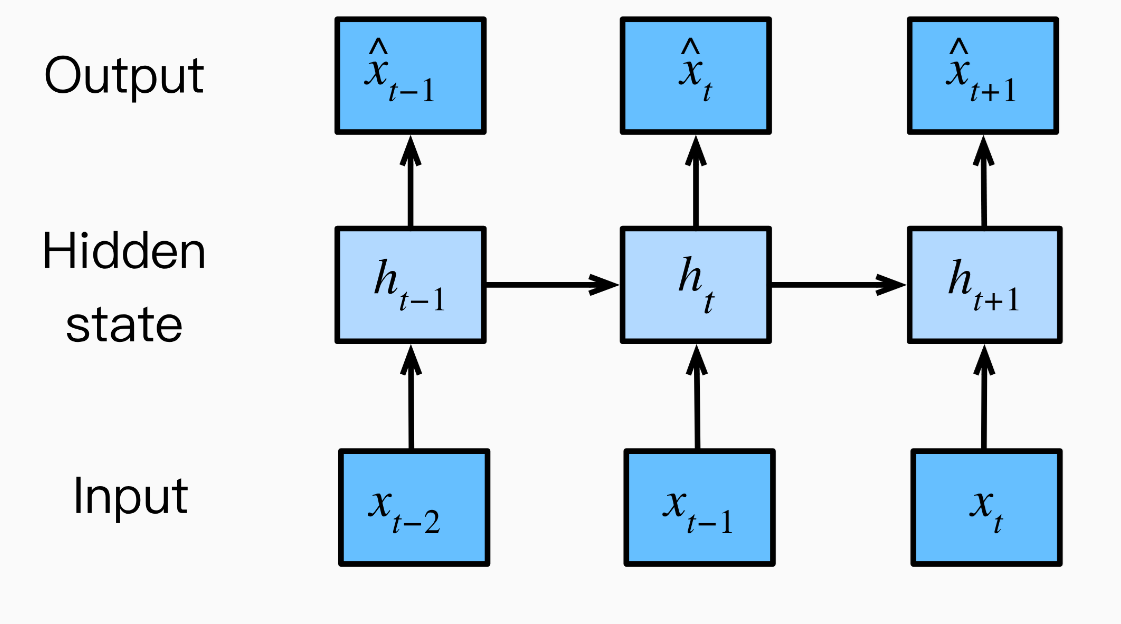


The figure shows how the model processes a sequence over time.

- **Input $x_t$:** the observation at the current time step.
- **Hidden state $h_t$:** the model's current memory of previous information.
- **Prediction $\hat{x}_t$:** the output produced using that memory.
- The hidden state is passed forward:

$$
h_{t-1} \rightarrow h_t \rightarrow h_{t+1}
$$

At each step, the model combines the **previous hidden state** with the **new input** to update its memory.

> **Important:** This idea of passing a hidden state from one time step to the next is the foundation of an **RNN**.

## Sequence Models

Autoregressive models showed how previous observations can be used to predict the **next value**.

A **sequence model** extends this idea to model an entire sequence:

$$
P(x_1, x_2, \ldots, x_T)
$$

This represents the probability of observing the complete sequence.

Using the chain rule, this probability can be expressed as a series of next-step predictions:

$$
P(x_1, \ldots, x_T)
=
P(x_1)
P(x_2 \mid x_1)
P(x_3 \mid x_1,x_2)
\cdots
P(x_T \mid x_1,\ldots,x_{T-1})
$$

This means that the probability of the whole sequence is built by repeatedly asking:

> **Given what we have observed so far, how likely is the next value?**

For example, in language modeling, we repeatedly predict the probability of the **next word or token** based on the words that came before it.

> **Key idea:** A sequence model describes an entire sequence by combining a series of next-step predictions.

### Training an Autoregressive Model

Earlier, we introduced the **fixed-window approach** for autoregressive models: instead of using the entire history of a sequence, we use only the most recent $\tau$ observations to predict the next value.

**This example now shows how that idea is actually used to create training data and train a model.**

First, we create a synthetic time series:

$$
x_t = \sin(0.01t) + \text{noise}
$$

The model's task is:

> **Given the previous $\tau$ values, predict the next value.**

If we choose $\tau = 4$, each training example looks like:

$$
[x_{t-4},x_{t-3},x_{t-2},x_{t-1}]
\rightarrow x_t
$$

For example:

$$
[x_1,x_2,x_3,x_4] \rightarrow x_5
$$

$$
[x_2,x_3,x_4,x_5] \rightarrow x_6
$$

$$
[x_3,x_4,x_5,x_6] \rightarrow x_7
$$

The window moves forward one step at a time, turning **one long sequence into many input-label training examples**.

A linear regression model is then trained on these examples to learn how the recent values can be used to predict the next value.

> **Why are we doing this?**  
> This is the practical implementation of the fixed-window autoregressive idea introduced earlier. It shows how sequential data can be converted into a standard supervised learning problem before we move on to more advanced sequence models such as RNNs.

In [ ]:
!pip install --q d2l --no-deps

In [ ]:
import tensorflow as tf
from d2l import tensorflow as d2l

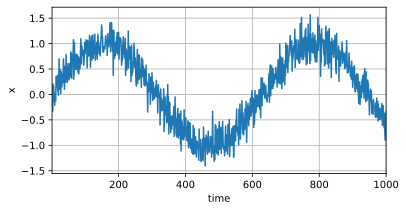

In [ ]:
# Create a dataset class for our time-series example.
class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        # Save parameters such as T, num_train, and tau.
        self.save_hyperparameters()

        # Create time steps from 1 to 1000.
        self.time = tf.range(1, T + 1, dtype=tf.float32)

        # Create the sequence:
        # sine-wave pattern + random noise.
        self.x = tf.sin(0.01 * self.time) + tf.random.normal([T]) * 0.2


# Create the dataset.
data = Data()

# Plot the original sequence.
d2l.plot(
    data.time,
    data.x,
    'time',
    'x',
    xlim=[1, 1000],
    figsize=(6, 3)
)

### What did we create?

The graph above is our **original sequence of 1,000 values**.

At this point, we have **not created the training examples yet**.  
We only created the time series:

$$
x_1, x_2, x_3, \ldots, x_{1000}
$$

Next, we will reorganize this sequence into training data using $\tau=4$:

| $X_1$ | $X_2$ | $X_3$ | $X_4$ | Label |
|---|---|---|---|---|
| $x_1$ | $x_2$ | $x_3$ | $x_4$ | $x_5$ |
| $x_2$ | $x_3$ | $x_4$ | $x_5$ | $x_6$ |
| $x_3$ | $x_4$ | $x_5$ | $x_6$ | $x_7$ |

> We are not creating new values. We are reorganizing the existing sequence into **4 input features and 1 label** so that a model can learn to predict the next value.

In [ ]:
# Add a method to the Data class for creating the training
# and validation data.
@d2l.add_to_class(Data)
def get_dataloader(self, train):

    # Create tau feature columns from the sequence.
    # With tau=4, each row contains 4 consecutive past values.
    features = [
        self.x[i : self.T - self.tau + i]
        for i in range(self.tau)
    ]

    # Stack the 4 feature columns together.
    # Each row is now one input example:
    # [x_(t-4), x_(t-3), x_(t-2), x_(t-1)]
    self.features = tf.stack(features, 1)

    # The value immediately after those 4 values becomes the label.
    # This is the value that the model should learn to predict.
    self.labels = tf.reshape(
        self.x[self.tau:],
        (-1, 1)
    )

    # Use the first num_train examples for training.
    # Use the remaining examples for validation.
    i = (
        slice(0, self.num_train)
        if train
        else slice(self.num_train, None)
    )

    # Package the features and labels into batches.
    return self.get_tensorloader(
        [self.features, self.labels],
        train,
        i
    )


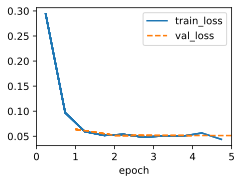

In [ ]:
# Create a linear regression model.
# It will learn to predict the next value from the previous 4 values.
model = d2l.LinearRegression(lr=0.01)

# Define Mean Squared Error (MSE) as the loss function.
# It measures the difference between the predicted next value
# and the actual next value.
model.loss = tf.keras.losses.MeanSquaredError()

# Create a trainer and train for 5 epochs.
trainer = d2l.Trainer(max_epochs=5)

# Train the model using the training examples created above.
trainer.fit(model, data)

### Training Results

The loss decreases quickly during the first few epochs and then stabilizes.

- **Training loss** shows how well the model fits the training examples.
- **Validation loss** shows how well the model performs on unseen examples.
- Since both losses are low and remain close to each other, the autoregressive model is learning the sequence pattern reasonably well.

> **Key idea:** The model has learned to use the previous 4 values to predict the next value in the sequence.

### Prediction with an Autoregressive Model

After training the model, we use it to predict future values.

#### One-Step-Ahead Prediction

The model uses the previous $\tau$ **actual values** to predict the next value.

For $\tau = 4$:

$$
[x_{t-4}, x_{t-3}, x_{t-2}, x_{t-1}]
\rightarrow \hat{x}_t
$$

Because the inputs are actual observed values, **one-step predictions are usually accurate**.

#### Multistep Prediction

If we want to predict several steps into the future, the actual future values are not available.  
The model must therefore use its **previous predictions as inputs**.

For example:

$$
\hat{x}_{605} = f(x_{601}, x_{602}, x_{603}, x_{604})
$$

$$
\hat{x}_{606} = f(x_{602}, x_{603}, x_{604}, \hat{x}_{605})
$$

As we predict farther into the future, more actual values are replaced by predicted values.

> **Key idea:** Errors can accumulate because an incorrect prediction becomes an input to later predictions. Therefore, predictions usually become less reliable as we predict farther into the future.

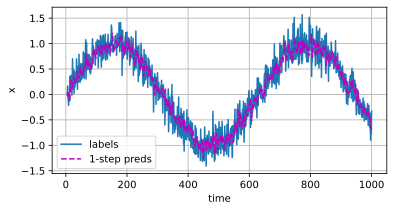

In [ ]:
# Use the trained model to make a prediction for every training example.
one_step_preds = model(data.features).numpy()

# Plot the actual values and the one-step-ahead predictions.
d2l.plot(
    data.time[data.tau:],
    [data.labels, one_step_preds],
    'time',
    'x',
    legend=['labels', '1-step preds'],
    figsize=(6, 3)
)

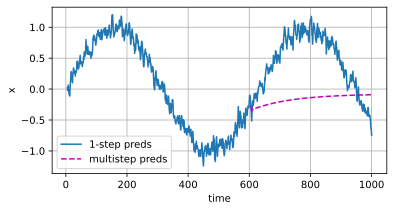

In [ ]:
# Create an array that will store the multistep predictions.
multistep_preds = tf.Variable(tf.zeros(data.T))

# Copy the actual observed values into the beginning of the array.
multistep_preds[:data.num_train + data.tau].assign(
    data.x[:data.num_train + data.tau]
)

# Predict future values one at a time.
for i in range(data.num_train + data.tau, data.T):

    # Use the previous tau values to predict the next value.
    # As we move forward, these inputs increasingly contain
    # the model's own previous predictions.
    multistep_preds[i].assign(
        tf.reshape(
            model(
                tf.reshape(
                    multistep_preds[i-data.tau:i],
                    (1, -1)
                )
            ),
            ()
        )
    )

# Compare one-step predictions with multistep predictions.
d2l.plot(
    [data.time[data.tau:], data.time[data.num_train + data.tau:]],
    [one_step_preds, multistep_preds[data.num_train + data.tau:]],
    'time',
    'x',
    legend=['1-step preds', 'multistep preds'],
    figsize=(6, 3)
)

#### What Are We Testing Here?

The previous figure tested **one-step prediction**, where the model always receives the previous 4 **actual values**.

Now we test a harder situation:

> **What happens if the real observations stop and the model must continue predicting the future by itself?**

The blue line shows the one-step predictions, which continue to use actual previous values.

The pink dashed line begins where we pretend that **no more actual values are available**. From that point forward:

1. The model predicts the next value.
2. That prediction is placed back into the 4-value input window.
3. The model uses that window to make another prediction.
4. This process repeats into the future.

For example:

$$
[x_{601},x_{602},x_{603},x_{604}]
\rightarrow \hat{x}_{605}
$$

Then:

$$
[x_{602},x_{603},x_{604},\hat{x}_{605}]
\rightarrow \hat{x}_{606}
$$

Then more predictions replace actual values:

$$
[x_{603},x_{604},\hat{x}_{605},\hat{x}_{606}]
\rightarrow \hat{x}_{607}
$$

> **What the graph shows:** The farther the model predicts into the future, the more it depends on its own previous predictions. Errors accumulate, causing the multistep prediction (pink dashed line) to drift away from the true sequence.

### What Does the Result Show?

The **one-step predictions** work well because the model always receives real previous values.

The **multistep predictions** become worse because the model must reuse its own predictions as inputs. Small prediction errors therefore accumulate over time.

> **Main takeaway:** A fixed-window autoregressive model can predict the near future well, but it struggles with longer-term dependencies. This motivates sequence models that can carry information through time, such as **RNNs**.

### Summary

- **Sequence data has temporal order** — future observations should not be used to predict the past.
- **Autoregressive models** predict future values using previous values in the sequence.
- A **fixed window** uses only the most recent $\tau$ observations.
- **One-step-ahead predictions** are usually easier because recent actual observations are available.
- For **multistep predictions**, the model increasingly relies on its own previous predictions.
- As we predict farther into the future, **errors accumulate and prediction quality decreases**.

> Predicting sequences becomes harder as we look farther into the future. This motivates more powerful sequence models that can better represent information from the past.